# traj_refiner.py

## （1）根据配置决定是否创建 Bev_refiner 网络，用于进一步处理 BEV 特征与轨迹特征。

```python
if self.traj_bev:
    self.Bev_refiner = Bev_refiner(
        config,
        config.proposal_num,
        self.poses_num,
        config.traj_proposal_query
    )
```


## （2）创建一个多层感知机（MLP），将高维轨迹特征转换为车辆的轨迹状态。

```python
self.traj_decoder = MLP(
    config.tf_d_model,
    config.tf_d_ffn,
    self.state_size
)
```
| 参数 | 含义 | 假设值 |
| ---- | ---- | ---- |
| config.tf_d_model | 输入特征维度 | 256 |
| config.tf_d_ffn | 隐藏层维度 | 512 |
| self.state_size | 输出状态维度 | 3 |

因此，相当于:
```python
self.traj_decoder = MLP(256, 512, 3)
```
工作流程：
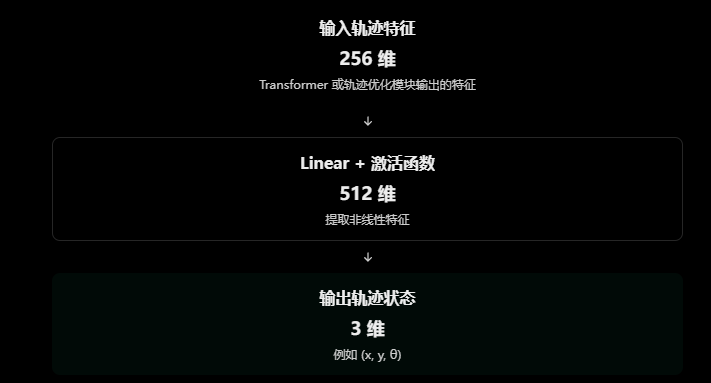
数学表达式为：
$
h=\sigma(W_1z+b_1)
$
$
p=W_2h+b_2
$

其中：
- $z \in \mathbb{R} ^{256}$：输入特征。
- $h \in \mathbb{R} ^ {512}$：隐藏层特征。
- $p \in \mathbb{R} ^ 3$：输出状态。
- $\sigma$：非线性激活函数，例如 ReLU。